In [13]:
import time
import numpy as np
from pathlib import Path
import orjson as json
from collections import Counter
import matplotlib.pyplot as plt

USE_BYTES = True

In [6]:
file_path = Path("local/2026-09-10-2/test_output/index_rqvae_prod.json")  # Replace with your actual file path

print(f"Loading '{file_path.name}' ({file_path.stat().st_size / (1024**3):.2f} GB)...")
start_time = time.time()

with open(file_path, "rb") as f:
    data = json.loads(f.read())

elapsed = time.time() - start_time
print(f"Successfully loaded {len(data):,} items in {elapsed:.2f} seconds!")


for i, (k, v) in enumerate(data.items()):
    if i >= 3:
        break
    print(f"Key: {k} | Semantic IDs: {v}")

Loading 'index_rqvae_prod.json' (0.20 GB)...
Successfully loaded 4,896,667 items in 5.42 seconds!
Key: 20000000271 | Semantic IDs: [68, 82, 30, 39, 217, 0]
Key: 20000000511 | Semantic IDs: [223, 83, 7, 222, 138, 0]
Key: 20000000520 | Semantic IDs: [243, 109, 221, 225, 54, 0]


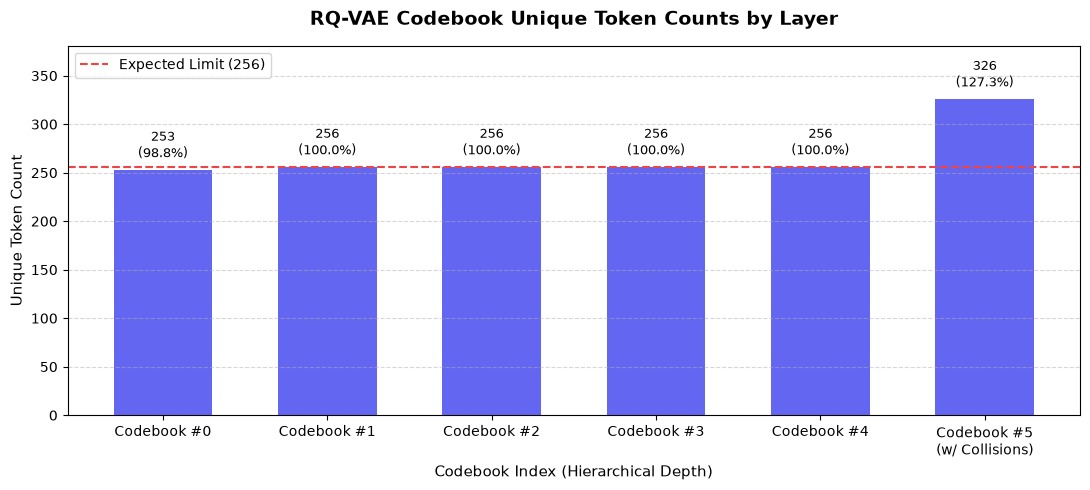

In [19]:
# Convert dictionary values to a numpy array for fast column-wise operations
all_clusters_tensor = np.array(list(data.values()))
num_items, num_codebooks = all_clusters_tensor.shape

base_codebook_size = 256  # Expected size limit
unique_counts = []
cb_labels = []

for cb_idx in range(num_codebooks):
    cb_assignments = all_clusters_tensor[:, cb_idx]
    num_unique = len(np.unique(cb_assignments))
    unique_counts.append(num_unique)
    
    if cb_idx == num_codebooks - 1:
        cb_labels.append(f"Codebook #{cb_idx}\n(w/ Collisions)")
    else:
        cb_labels.append(f"Codebook #{cb_idx}")

# Plotting Codebook Utilization (Counts & Percentages)
fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(cb_labels, unique_counts, color="#6366f1", width=0.6, edgecolor="none")

# Add a dashed line for the expected 256 codebook size limit
ax.axhline(base_codebook_size, color="#ef4444", linestyle="--", linewidth=1.5, label=f"Expected Limit ({base_codebook_size})")

# Value labels on top of bars showing both count and percentage
for bar, unique in zip(bars, unique_counts):
    height = bar.get_height()
    pct = (unique / base_codebook_size) * 100.0
    ax.annotate(
        f"{unique:,}\n({pct:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),  # 6 points vertical offset
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="medium"
    )

ax.set_title("RQ-VAE Codebook Unique Token Counts by Layer", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Codebook Index (Hierarchical Depth)", fontsize=11)
ax.set_ylabel("Unique Token Count", fontsize=11)

# Give ample headroom so annotations and legend don't clash
ax.set_ylim(0, max(max(unique_counts) + 55, base_codebook_size + 60)) 

# Move legend to upper left to keep it clear of the rightmost collision bar
ax.legend(loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Calculations completed in 9.66 seconds.


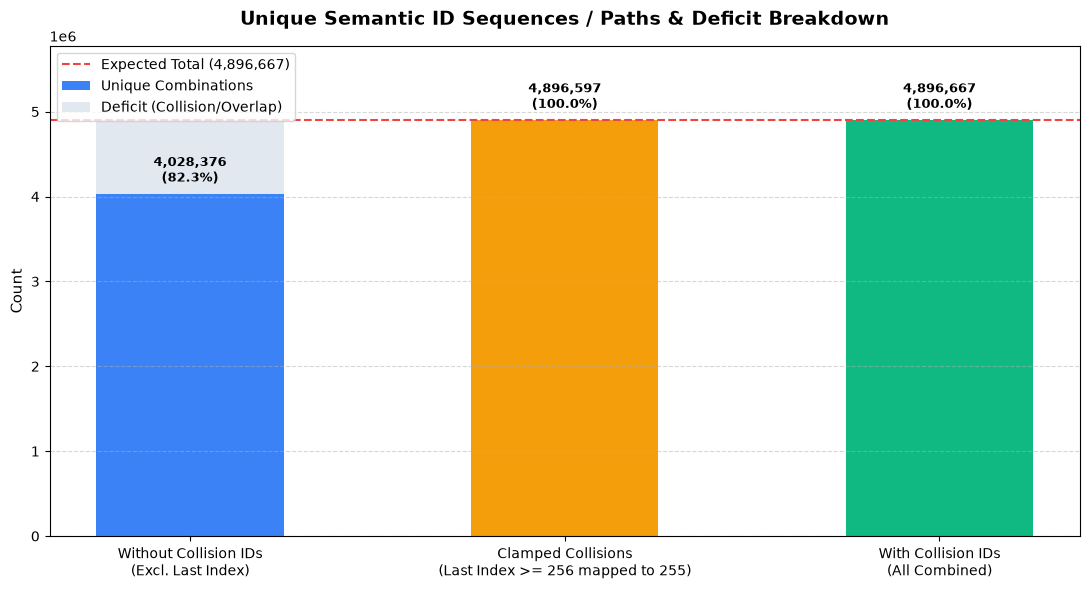

In [26]:
start_time = time.time()

total_entries = len(data)

# 1. Fast set-based unique sequence calculations
tuples_without = [tuple(v[:-1]) for v in data.values() if len(v) > 1]
unique_count_without = len(set(tuples_without))

tuples_clamped = []
for v in data.values():
    if len(v) > 0:
        lst = list(v)
        if lst[-1] >= 256:
            lst[-1] = 255
        tuples_clamped.append(tuple(lst))
unique_count_clamped = len(set(tuples_clamped))

tuples_with = [tuple(v) for v in data.values()]
unique_count_with = len(set(tuples_with))

print(f"Calculations completed in {time.time() - start_time:.2f} seconds.")

# --- Plotting Stacked Bars (Actual + Deficit to Expected Total) ---
categories = [
    "Without Collision IDs\n(Excl. Last Index)", 
    "Clamped Collisions\n(Last Index >= 256 mapped to 255)", 
    "With Collision IDs\n(All Combined)"
]

actual_counts = [unique_count_without, unique_count_clamped, unique_count_with]
deficits = [total_entries - count for count in actual_counts]

fig, ax = plt.subplots(figsize=(11, 6))

# Main bars (Actual Unique Counts)
bars_actual = ax.bar(categories, actual_counts, width=0.5, color=["#3b82f6", "#f59e0b", "#10b981"], edgecolor="none", label="Unique Combinations")
# Deficit bars (Stacked on top)
bars_deficit = ax.bar(categories, deficits, bottom=actual_counts, width=0.5, color="#e2e8f0", edgecolor="none", label="Deficit (Collision/Overlap)")

# Value labels on top of actual bars
for bar, count in zip(bars_actual, actual_counts):
    height = bar.get_height()
    pct = (count / total_entries) * 100.0
    ax.annotate(
        f"{count:,}\n({pct:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

ax.axhline(total_entries, color="#ef4444", linestyle="--", linewidth=1.5, label=f"Expected Total ({total_entries:,})")

ax.set_title("Unique Semantic ID Sequences / Paths & Deficit Breakdown", fontsize=14, fontweight="bold", pad=15)
ax.set_ylabel("Count", fontsize=11)
ax.set_ylim(0, total_entries * 1.18)  # Headroom for annotations
ax.legend(loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

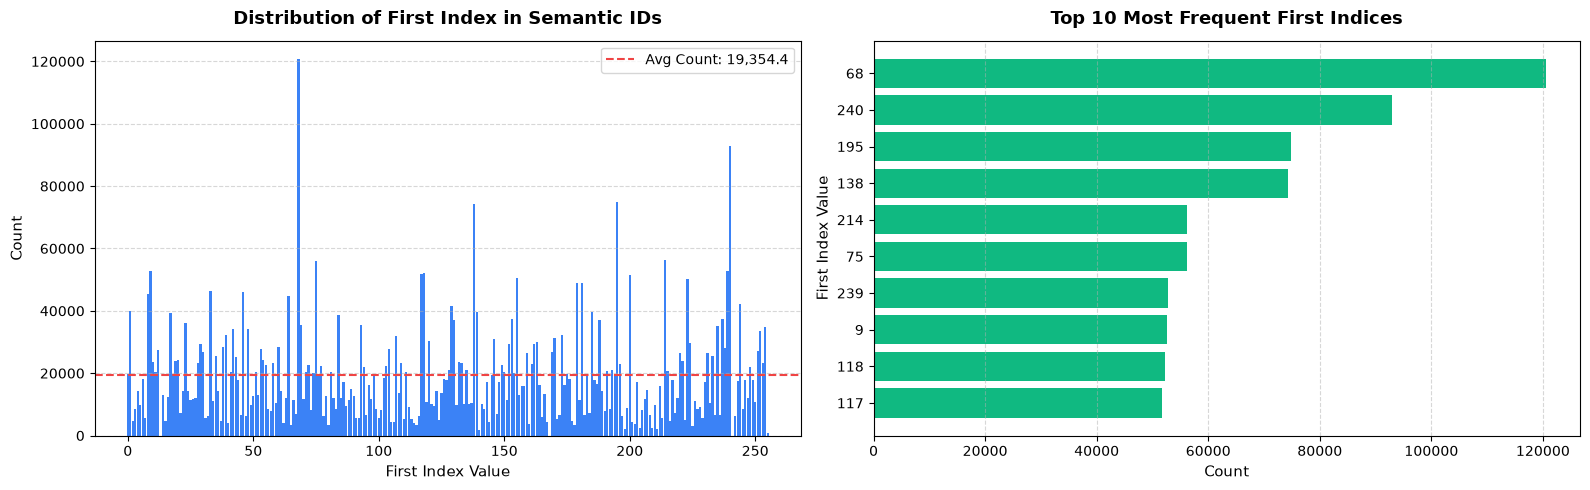

In [11]:
# Extract the first element from each semantic ID list
first_indices = [v[0] for v in data.values() if len(v) > 0]

# Count the frequencies
counts = Counter(first_indices)

# Sort by the index value for the full distribution chart
sorted_keys = sorted(counts.keys())
sorted_counts = [counts[k] for k in sorted_keys]

# Create figure with 2 subplots side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# --- Subplot 1: Full Distribution Bar Chart with Average Dashed Line ---
ax1.bar(sorted_keys, sorted_counts, width=0.9, color="#3b82f6", edgecolor="none")
mean_count = sum(sorted_counts) / len(sorted_counts) if sorted_counts else 0
ax1.axhline(
    mean_count,
    color="#ef4444",
    linestyle="--",
    linewidth=1.5,
    label=f"Avg Count: {mean_count:,.1f}",
)

ax1.set_title("Distribution of First Index in Semantic IDs", fontsize=13, fontweight="bold", pad=12)
ax1.set_xlabel("First Index Value", fontsize=11)
ax1.set_ylabel("Count", fontsize=11)
ax1.legend(loc="upper right")
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# --- Subplot 2: Horizontal Sorted Bar Chart for Top 10 Most Frequent ---
top_10 = counts.most_common(10)
# Reverse to have the highest at the top in horizontal layout
top_10_sorted = sorted(top_10, key=lambda x: x[1])
top_keys = [str(item[0]) for item in top_10_sorted]
top_vals = [item[1] for item in top_10_sorted]

ax2.barh(top_keys, top_vals, color="#10b981", edgecolor="none")
ax2.set_title("Top 10 Most Frequent First Indices", fontsize=13, fontweight="bold", pad=12)
ax2.set_xlabel("Count", fontsize=11)
ax2.set_ylabel("First Index Value", fontsize=11)
ax2.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()